In [1]:
import os
import datetime
import tensorflow as tf
from tensorflow.keras import layers, Model
import matplotlib.pyplot as plt
import numpy as np
import plotly.express as px
import pandas as pd
from sklearn.decomposition import PCA

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    tf.config.experimental.set_memory_growth(gpus[0], True)

2026-03-02 22:49:48.849941: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-03-02 22:49:48.849990: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-03-02 22:49:48.851242: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-03-02 22:49:48.858467: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-03-02 22:49:49.619678: W tensorflow/compiler/tf2

In [2]:
!pip list

Package                      Version
---------------------------- -----------
absl-py                      2.4.0
anyio                        4.12.1
argon2-cffi                  25.1.0
argon2-cffi-bindings         25.1.0
arrow                        1.4.0
asttokens                    3.0.1
astunparse                   1.6.3
async-lru                    2.2.0
attrs                        25.4.0
babel                        2.18.0
beautifulsoup4               4.14.3
bleach                       6.3.0
certifi                      2026.2.25
cffi                         2.0.0
charset-normalizer           3.4.4
colorgram.py                 1.2.0
comm                         0.2.3
contourpy                    1.3.2
cryptography                 46.0.5
cycler                       0.12.1
debugpy                      1.8.20
decorator                    5.2.1
defusedxml                   0.7.1
exceptiongroup               1.3.1
executing                    2.2.1
fastjsonschema               2.21.

In [3]:
# ==============================================================================
# Utility Classes
# ==============================================================================

def build_vgg_extractor():
    """
    Extrae features de dos niveles:
    - block1_conv2 → texturas finas, bordes
    - block3_conv3 → estructuras, formas
    """
    vgg = tf.keras.applications.VGG16(
        include_top=False,
        weights="imagenet",
        input_shape=(64, 64, 3)
    )
    vgg.trainable = False
    outputs = [
        vgg.get_layer("block1_conv2").output,
        vgg.get_layer("block3_conv3").output,
    ]
    return tf.keras.Model(vgg.input, outputs, name="vgg_extractor")

vgg_extractor = build_vgg_extractor()


def perceptual_loss(x_real, x_recon):
    x_real_vgg  = tf.keras.applications.vgg16.preprocess_input(x_real  * 255.0)
    x_recon_vgg = tf.keras.applications.vgg16.preprocess_input(x_recon * 255.0)
    feats_real  = vgg_extractor(x_real_vgg,  training=False)
    feats_recon = vgg_extractor(x_recon_vgg, training=False)
    loss = 0.0
    for f_real, f_recon in zip(feats_real, feats_recon):
        loss += tf.reduce_mean(tf.square(f_real - f_recon))
    return loss

class Sampling(layers.Layer):
    """Reparametrization trick: z = mean + exp(0.5 * log_var) * epsilon."""
    def call(self, inputs):
        z_mean, z_log_var = inputs
        epsilon = tf.random.normal(shape=tf.shape(z_mean))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon


2026-03-02 22:49:51.893141: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2026-03-02 22:49:51.893558: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2026-03-02 22:49:51.893879: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-

In [4]:
# ==============================================================================
# DATASET
# ==============================================================================

train_dir  = os.path.join("..", "..", "Dataset", "preprocessed", "train")
test_dir  = os.path.join("..", "..", "Dataset", "preprocessed", "test")

batch_size = 16  # Reducido de 32 por VGG en VRAM

train_dataset = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    labels=None,
    image_size=(64, 64),
    shuffle=True,
    batch_size=batch_size,
)

test_dataset = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    labels=None,
    image_size=(64, 64),
    shuffle=True,
    batch_size=batch_size,
)

train_dataset = train_dataset.map(lambda x: tf.cast(x, tf.float32) / 255.0)
train_dataset = train_dataset.prefetch(tf.data.AUTOTUNE)

test_dataset = test_dataset.map(lambda x: tf.cast(x, tf.float32) / 255.0)
test_dataset = test_dataset.prefetch(tf.data.AUTOTUNE)



Found 241 files belonging to 1 classes.
Found 13 files belonging to 1 classes.


In [5]:
# ==============================================================================
# Arquitectura: Convolutional VAE
# ==============================================================================

img_shape  = (64, 64, 3)
latent_dim = 128

class ConvVAE(Model):
    """
    VAE convolucional con perdida ELBO + Perceptual Loss:
        loss = reconstruction_loss + beta * kl_loss + lambda * perceptual_loss

    beta=1  -> VAE estandar (Kingma & Welling 2013)
    beta>1  -> beta-VAE (mejor disentanglement, menor fidelidad)
    lam     -> peso de VGG perceptual loss
    """
    def __init__(self, latent_dim, beta=1.0, lam=0.1):
        super().__init__()
        self.latent_dim = latent_dim
        self.beta       = beta
        self.lam        = lam

        self.encoder_conv = tf.keras.Sequential([
            layers.Conv2D(32,  3, strides=2, padding="same", activation="relu"),
            layers.Conv2D(64,  3, strides=2, padding="same", activation="relu"),
            layers.Conv2D(128, 3, strides=2, padding="same", activation="relu"),
            layers.Conv2D(256, 3, strides=2, padding="same", activation="relu"),
            layers.Conv2D(512, 3, strides=2, padding="same", activation="relu"),
            layers.Flatten(),
            layers.Dense(256, activation="relu"),
        ], name="encoder_conv")

        self.z_mean_layer    = layers.Dense(latent_dim, name="z_mean")
        self.z_log_var_layer = layers.Dense(latent_dim, name="z_log_var")
        self.sampling        = Sampling()

        self.decoder = tf.keras.Sequential([
            layers.Dense(2 * 2 * 512, activation="relu"),
            layers.Reshape((2, 2, 512)),
            layers.Conv2DTranspose(256, 3, strides=2, padding="same", activation="relu"),
            layers.Conv2DTranspose(128, 3, strides=2, padding="same", activation="relu"),
            layers.Conv2DTranspose(64,  3, strides=2, padding="same", activation="relu"),
            layers.Conv2DTranspose(32,  3, strides=2, padding="same", activation="relu"),
            layers.Conv2DTranspose(16,  3, strides=2, padding="same", activation="relu"),
            layers.Conv2DTranspose(3,   3, padding="same", activation="sigmoid"),
        ], name="decoder")

    def encode(self, x):
        h         = self.encoder_conv(x)
        z_mean    = self.z_mean_layer(h)
        z_log_var = self.z_log_var_layer(h)
        z         = self.sampling([z_mean, z_log_var])
        return z_mean, z_log_var, z

    def decode(self, z):
        return self.decoder(z)

    def call(self, x, training=False):
        z_mean, z_log_var, z = self.encode(x)
        x_reconstructed      = self.decode(z)
        return x_reconstructed, z_mean, z_log_var

    def _compute_losses(self, x, x_reconstructed, z_mean, z_log_var):
        reconstruction_loss = tf.reduce_mean(
            tf.reduce_sum(tf.square(x - x_reconstructed), axis=[1, 2, 3])
        )
        kl_loss = -0.5 * tf.reduce_mean(
            tf.reduce_sum(1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var), axis=1)
        )
        p_loss = perceptual_loss(x, x_reconstructed)
        total  = reconstruction_loss + self.beta * kl_loss + self.lam * p_loss
        return total, reconstruction_loss, kl_loss, p_loss

    def train_step(self, x):
        with tf.GradientTape() as tape:
            x_rec, z_mean, z_log_var    = self(x, training=True)
            total, recon, kl, p         = self._compute_losses(x, x_rec, z_mean, z_log_var)
        grads = tape.gradient(total, self.trainable_variables)
        self.optimizer.apply_gradients(zip(grads, self.trainable_variables))
        return {
            "loss":                total,
            "reconstruction_loss": recon,
            "kl_loss":             kl,
            "perceptual_loss":     p,
        }

    def test_step(self, x):
        x_rec, z_mean, z_log_var = self(x, training=False)
        total, recon, kl, p      = self._compute_losses(x, x_rec, z_mean, z_log_var)
        return {
            "loss":                total,
            "reconstruction_loss": recon,
            "kl_loss":             kl,
            "perceptual_loss":     p,
        }


In [6]:
# ==============================================================================
# INSTANCIA, COMPILACIÓN
# ==============================================================================

lr_schedule = tf.keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=1e-3,
    decay_steps=2000 * 6,
    alpha=1e-6,
)

cvae = ConvVAE(latent_dim=latent_dim, beta=1, lam=0.0001)
cvae.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr_schedule))

In [7]:
# ==============================================================================
# ENTRENAMIENTO
# ==============================================================================
cvae.fit(
    train_dataset,
    epochs=2000,
)

Epoch 1/2000


2026-03-02 22:49:56.057199: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:454] Loaded cuDNN version 8907
2026-03-02 22:49:59.020641: I external/local_xla/xla/service/service.cc:168] XLA service 0x71f895e3dd70 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-03-02 22:49:59.020680: I external/local_xla/xla/service/service.cc:176]   StreamExecutor device (0): NVIDIA GeForce GTX 1050 Ti, Compute Capability 6.1
2026-03-02 22:49:59.025811: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1772513399.115723  421604 device_compiler.h:186] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


16/16 [==============================] - 11s 167ms/step - loss: 2067.8155 - reconstruction_loss: 2000.1334 - kl_loss: 7.8149 - perceptual_loss: 598673.0147
Epoch 2/2000
16/16 [==============================] - 1s 55ms/step - loss: 1151.0983 - reconstruction_loss: 1080.5075 - kl_loss: 15.1831 - perceptual_loss: 554078.2757
Epoch 3/2000
16/16 [==============================] - 1s 52ms/step - loss: 922.4173 - reconstruction_loss: 853.3563 - kl_loss: 15.6633 - perceptual_loss: 533976.9485
Epoch 4/2000
16/16 [==============================] - 1s 52ms/step - loss: 843.6414 - reconstruction_loss: 779.3358 - kl_loss: 15.8344 - perceptual_loss: 484712.1673
Epoch 5/2000
16/16 [==============================] - 1s 56ms/step - loss: 778.3448 - reconstruction_loss: 716.7441 - kl_loss: 16.8467 - perceptual_loss: 447539.8125
Epoch 6/2000
16/16 [==============================] - 1s 56ms/step - loss: 736.0375 - reconstruction_loss: 669.2271 - kl_loss: 22.6068 - perceptual_loss: 442035.5276
Epoch 7/2000

In [17]:
cvae.summary()
cvae.save("cvae_model")

Model: "conv_vae"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 encoder_conv (Sequential)   (None, 256)               2093120   
                                                                 
 z_mean (Dense)              multiple                  32896     
                                                                 
 z_log_var (Dense)           multiple                  32896     
                                                                 
 sampling (Sampling)         multiple                  0         
                                                                 
 decoder (Sequential)        (None, 64, 64, 3)         1836451   
                                                                 
Total params: 3995363 (15.24 MB)
Trainable params: 3995363 (15.24 MB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________
INFO:tensorflow:Un

INFO:tensorflow:Unsupported signature for serialization: ((TensorSpec(shape=(3, 3, 3, 32), dtype=tf.float32, name='gradient'), <tensorflow.python.framework.func_graph.UnknownArgument object at 0x71fae0388730>, 125322363157552), {}).


INFO:tensorflow:Unsupported signature for serialization: ((TensorSpec(shape=(32,), dtype=tf.float32, name='gradient'), <tensorflow.python.framework.func_graph.UnknownArgument object at 0x71fae0388ca0>, 125324666897648), {}).


INFO:tensorflow:Unsupported signature for serialization: ((TensorSpec(shape=(32,), dtype=tf.float32, name='gradient'), <tensorflow.python.framework.func_graph.UnknownArgument object at 0x71fae0388ca0>, 125324666897648), {}).


INFO:tensorflow:Unsupported signature for serialization: ((TensorSpec(shape=(3, 3, 32, 64), dtype=tf.float32, name='gradient'), <tensorflow.python.framework.func_graph.UnknownArgument object at 0x71fae038b520>, 125322363300768), {}).


INFO:tensorflow:Unsupported signature for serialization: ((TensorSpec(shape=(3, 3, 32, 64), dtype=tf.float32, name='gradient'), <tensorflow.python.framework.func_graph.UnknownArgument object at 0x71fae038b520>, 125322363300768), {}).


... (112 outputs left out)

INFO:tensorflow:Unsupported signature for serialization: ((TensorSpec(shape=(3,), dtype=tf.float32, name='gradient'), <tensorflow.python.framework.func_graph.UnknownArgument object at 0x71fae01953f0>, 125322363667280), {}).


INFO:tensorflow:Unsupported signature for serialization: ((TensorSpec(shape=(3,), dtype=tf.float32, name='gradient'), <tensorflow.python.framework.func_graph.UnknownArgument object at 0x71fae01953f0>, 125322363667280), {}).


INFO:tensorflow:Assets written to: cvae_model/assets


INFO:tensorflow:Assets written to: cvae_model/assets


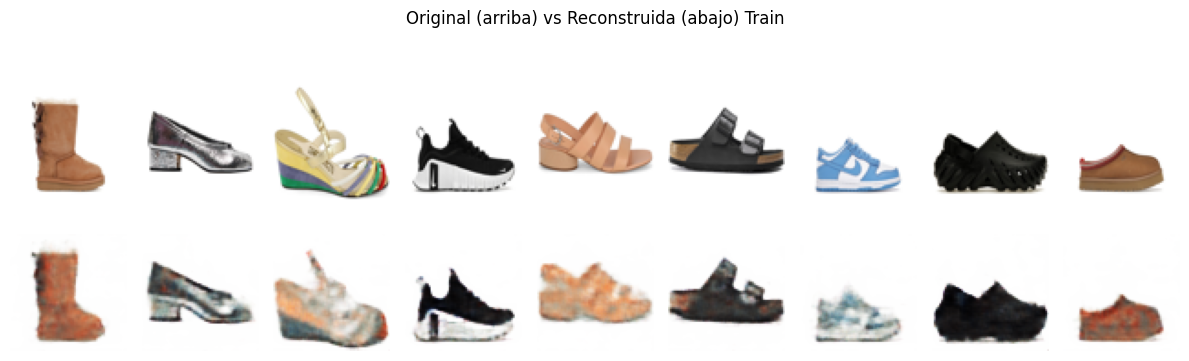

In [20]:
for batch in train_dataset.take(1):
    x_sample = batch[:9]

x_recon, _, _ = cvae.predict(x_sample, verbose=0)

plt.figure(figsize=(12, 4))
for i in range(9):
    plt.subplot(2, 9, i + 1)
    plt.imshow(x_sample[i].numpy())
    plt.axis("off")
    plt.subplot(2, 9, i + 10)
    plt.imshow(np.clip(x_recon[i], 0, 1))
    plt.axis("off")
plt.suptitle("Original (arriba) vs Reconstruida (abajo) Train")
plt.tight_layout()
plt.show()


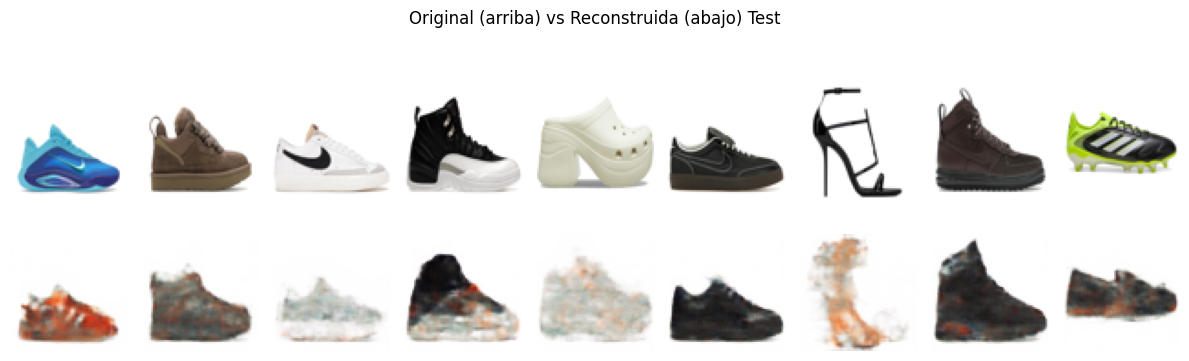

In [22]:
for batch in test_dataset.take(1):
    x_sample = batch[:9]

x_recon, _, _ = cvae.predict(x_sample, verbose=0)
plt.figure(figsize=(12, 4))

for i in range(9):
    plt.subplot(2, 9, i + 1)
    plt.imshow(x_sample[i].numpy())
    plt.axis("off")
    plt.subplot(2, 9, i + 10)
    plt.imshow(np.clip(x_recon[i], 0, 1))
    plt.axis("off")
plt.suptitle("Original (arriba) vs Reconstruida (abajo) Test")
plt.tight_layout()
plt.show()


In [23]:
def encode_batch(x):
    """Retorna z_mean (sin ruido) para visualizacion reproducible."""
    _, _, z = cvae.encode(x)
    return z

def decode_batch(z):
    return cvae.decode(z)

latent_vectors = []
original_images = []

for batch in train_dataset:
    z_mean, _, _ = cvae.encode(batch)
    latent_vectors.append(z_mean.numpy())
    original_images.append(batch.numpy())

latent_vectors  = np.vstack(latent_vectors)
original_images = np.vstack(original_images)
num_images      = len(latent_vectors)

print(f"Vectores latentes: {latent_vectors.shape}")
print(f"Imagenes totales:  {num_images}")


Vectores latentes: (241, 128)
Imagenes totales:  241


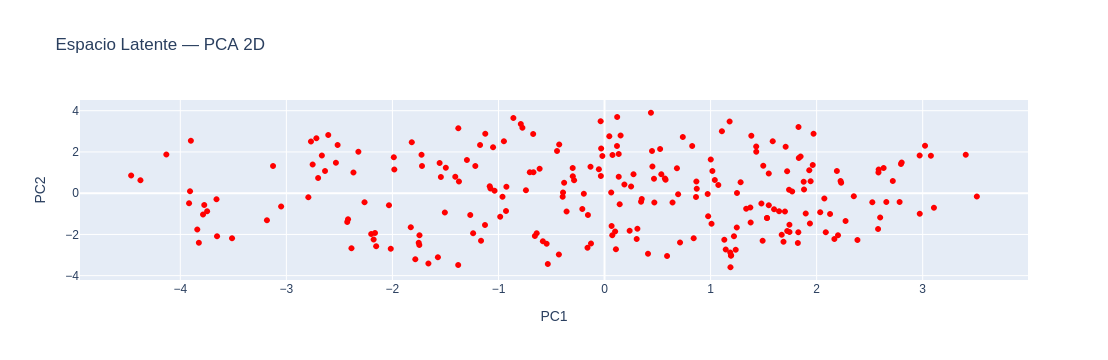

In [12]:
pca        = PCA(n_components=2)
latent_pca = pca.fit_transform(latent_vectors)

df = pd.DataFrame({
    "PC1":   latent_pca[:, 0],
    "PC2":   latent_pca[:, 1],
    "index": np.arange(num_images),
})

fig = px.scatter(df, x="PC1", y="PC2", hover_data=["index"],
                 title="Espacio Latente — PCA 2D")
fig.update_traces(marker=dict(color="red", size=6))
fig.show()

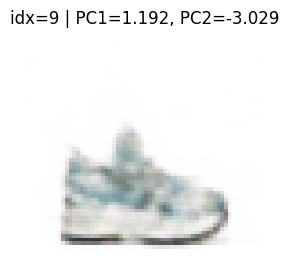

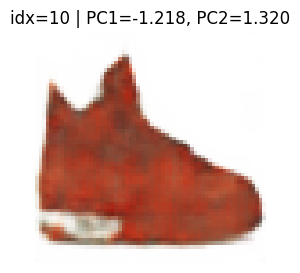

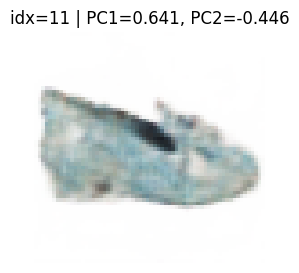

In [13]:
def show_image(idx):
    z   = latent_vectors[idx:idx+1]
    pc1, pc2 = latent_pca[idx]
    img = cvae.decode(tf.constant(z)).numpy()[0]
    plt.figure(figsize=(3, 3))
    plt.imshow(np.clip(img, 0, 1))
    plt.axis("off")
    plt.title(f"idx={idx} | PC1={pc1:.3f}, PC2={pc2:.3f}")
    plt.show()

show_image(9)
show_image(min(10, num_images - 1))
show_image(min(11, num_images - 1))


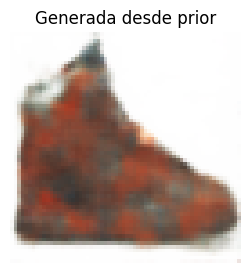

In [32]:
z_new = np.random.normal(0, 1, size=(1, latent_dim)).astype("float32")
img   = cvae.decode(tf.constant(z_new)).numpy()[0]

plt.figure(figsize=(3, 3))
plt.imshow(np.clip(img, 0, 1))
plt.axis("off")
plt.title("Generada desde prior")
plt.show()

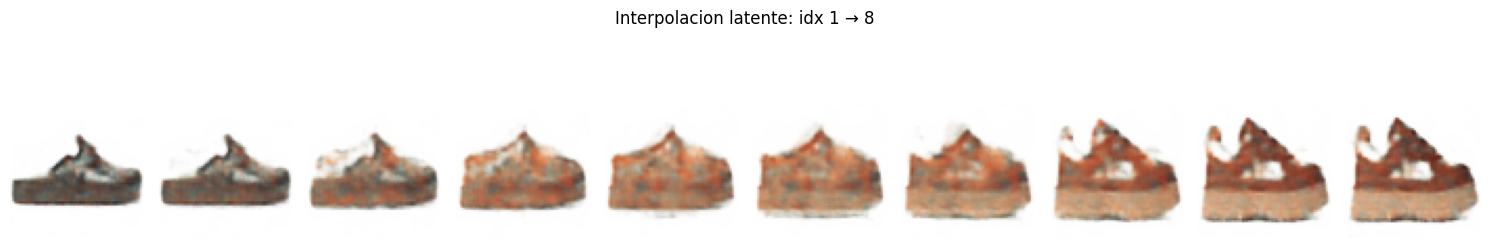

In [41]:
idx1 = min(1, num_images - 1)
idx2 = min(8,  num_images - 1)
z1, z2 = latent_vectors[idx1], latent_vectors[idx2]
steps  = 10

plt.figure(figsize=(15, 3))
for i, alpha in enumerate(np.linspace(0, 1, steps)):
    z_interp = ((1 - alpha) * z1 + alpha * z2).reshape(1, -1).astype("float32")
    img = cvae.decode(tf.constant(z_interp)).numpy()[0]
    plt.subplot(1, steps, i + 1)
    plt.imshow(np.clip(img, 0, 1))
    plt.axis("off")
plt.suptitle(f"Interpolacion latente: idx {idx1} → {idx2}")
plt.tight_layout()
plt.show()

2026-03-02 23:30:53.477003: W external/local_tsl/tsl/framework/bfc_allocator.cc:296] Allocator (GPU_0_bfc) ran out of memory trying to allocate 2.49GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.
2026-03-02 23:30:53.477055: W external/local_tsl/tsl/framework/bfc_allocator.cc:366] Garbage collection: deallocate free memory regions (i.e., allocations) so that we can re-allocate a larger region to avoid OOM due to memory fragmentation. If you see this message frequently, you are running near the threshold of the available device memory and re-allocation may incur great performance overhead. You may try smaller batch sizes to observe the performance impact. Set TF_ENABLE_GPU_GARBAGE_COLLECTION=false if you'd like to disable this feature.
2026-03-02 23:30:54.071710: W external/local_tsl/tsl/framework/bfc_allocator.cc:296] Allocator (GPU_0_bfc) ran out of memory trying to alloca

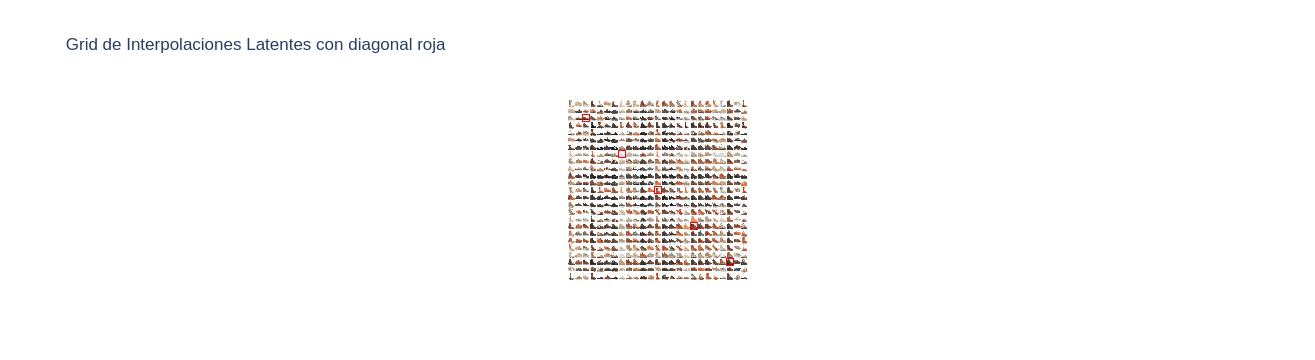

In [42]:
grid     = 25
z_matrix = []

for i in range(grid):
    for j in range(grid):
        z_interp = 0.5 * (latent_vectors[i] + latent_vectors[j])
        z_matrix.append(z_interp)

z_matrix = np.array(z_matrix).astype("float32")
imgs     = cvae.decode(tf.constant(z_matrix)).numpy()
imgs     = np.clip(imgs, 0, 1)

img_h, img_w, channels = imgs[0].shape
canvas = np.zeros((grid * img_h, grid * img_w, channels))

for i in range(grid):
    for j in range(grid):
        canvas[i*img_h:(i+1)*img_h, j*img_w:(j+1)*img_w] = imgs[i * grid + j]

border_thickness = 2
for d in range(grid):
    y_start, y_end = d*img_h, (d+1)*img_h
    x_start, x_end = d*img_w, (d+1)*img_w

    canvas[y_start:y_start+border_thickness, x_start:x_end] = [1, 0, 0]  # rojo
    canvas[y_end-border_thickness:y_end, x_start:x_end] = [1, 0, 0]

    canvas[y_start:y_end, x_start:x_start+border_thickness] = [1, 0, 0]
    canvas[y_start:y_end, x_end-border_thickness:x_end] = [1, 0, 0]

fig = px.imshow(canvas, title="Grid de Interpolaciones Latentes con diagonal roja")
fig.update_xaxes(showticklabels=False)
fig.update_yaxes(showticklabels=False)
fig.update_layout(dragmode="pan")
fig.show(config={"scrollZoom": True})